# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Pasion, Kyla Zarina
- _Student No._: 2024-09224
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

![Synthetic data interpolation](./Figures/e8_figure0.png)

**Figure 1. Synthetic data interpolation.** The figure compares a randomly sampled sine function reconstructed using linear, nearest, quadratic, and cubic interpolation methodinterpolations.

![Real-world data reconstruction](./Figures/e8_figure1.png)

**Figure 2. Real-world data reconstruction.** The four plots demonstrate the reconstruction of a Dow Jones time series across sampling fractions of 50%, 30%, 10%, and 5% using the same four interpolation methods

### Report discussion

**Interpolator comparison:** Figure 1 compares the linear, nearest, quadratic, and cubic interpolation methods applied to randomly sampled sine data. The cubic and quadratic interpolations most closely follow the true sine curve, with both reproducing its peaks, valleys, and smooth transitions with minimal visible deviation. Linear interpolation also approximates the overall shape well, although its straight-line segments produce slight differences in curvature between sampled points. In contrast, nearest interpolation produces a step-like curve that remains constant between neighboring sampled points, making it the least accurate representation of the smooth sine function. These results show that quadratic and cubic interpolation are more suitable for reconstructing smooth functions such as sine waves, while linear interpolation provides a simpler approximation. However, the performance of each method depends on the nature of the underlying data, and higher-order interpolation may not always be preferable for data with abrupt changes or irregular fluctuations.

**Sampling-level comparison:** Figure 2 shows how the sampling fraction affects the reconstruction of the Dow Jones time series. At sampling fractions of 50% and 30%, the interpolation curves closely follow the original data, capturing both the overall market trends and many of its smaller fluctuations. The differences between the methods are also relatively small because the sampled points provide sufficient information to reconstruct the series. At 10%, the curves still reproduce the general trend, including the major decline and subsequent recovery, but some local fluctuations are missed or inaccurately reconstructed. At 5%, the differences become more noticeable, particularly around sharp peaks, sudden declines, and regions with rapid changes. The quadratic and cubic interpolations exhibit overshooting and oscillations in some intervals, producing values that deviate from the original data, while nearest interpolation creates abrupt, step-like transitions. Linear interpolation provides a more direct connection between sampled points but cannot capture fluctuations that occur between them. Overall, the results indicate that reconstruction quality generally improves with a higher sampling fraction. However, accuracy also depends on which points are selected, since randomly sampled data may omit important features of the original time series. Interpolation can estimate values between known observations, but it cannot reliably recover market fluctuations that are not represented by the sampled points.

### Other comments
- None

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path
import pandas as pd

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

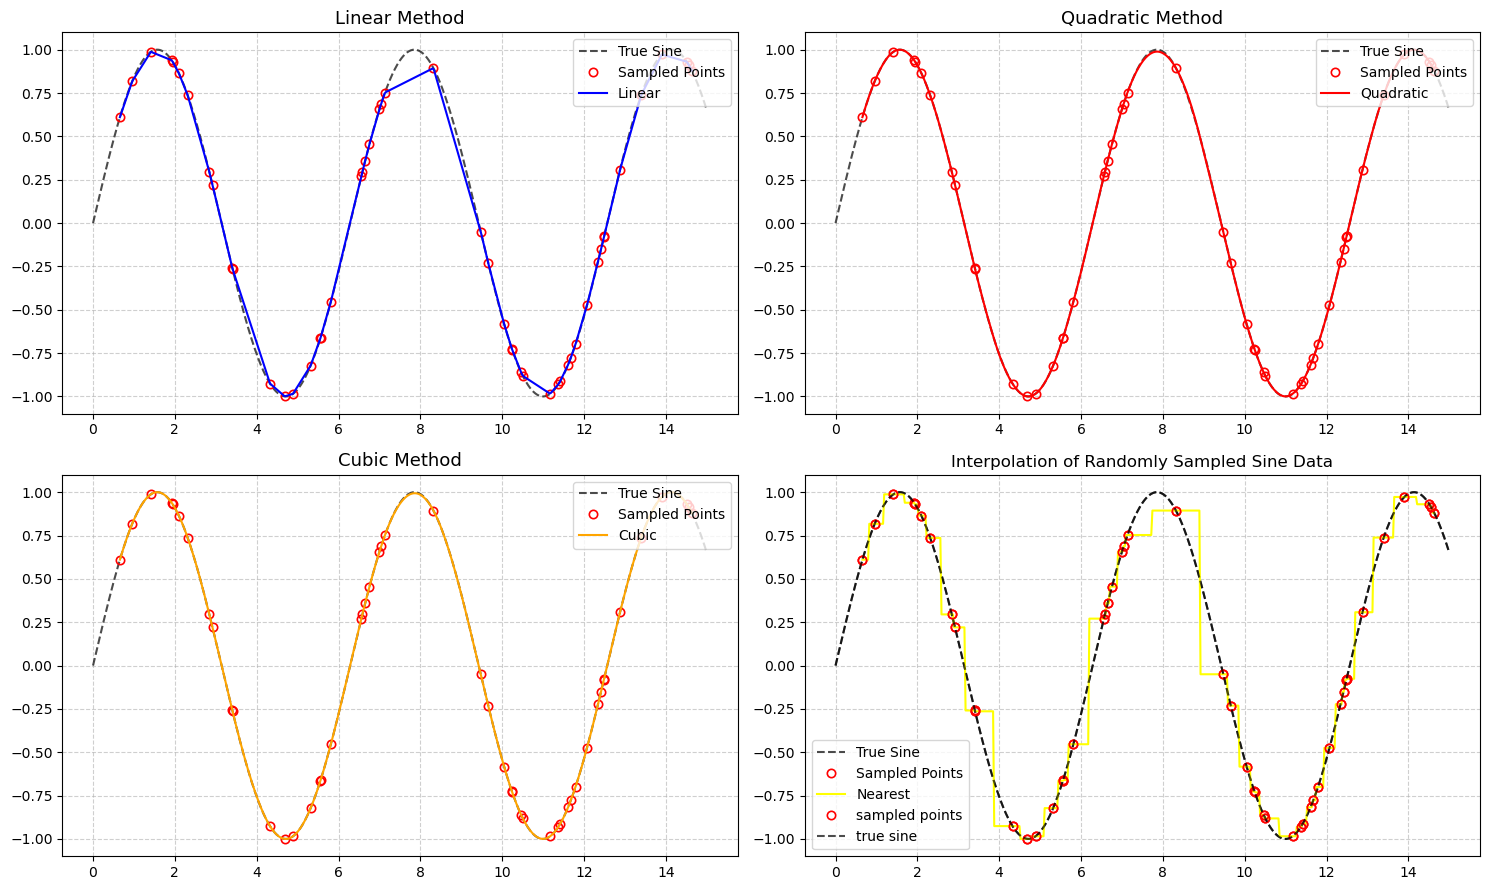

In [2]:
x = np.linspace(0, 15, 1000)
y = np.sin(x)

x_sample = np.sort(rng.uniform(0, 15, 50))
y_sample = np.sin(x_sample)

# Different interpolation methods
f_linear = interpolate.interp1d(x_sample, y_sample, kind='linear')
f_nearest = interpolate.interp1d(x_sample, y_sample, kind='nearest')
f_quadratic = interpolate.interp1d(x_sample, y_sample, kind='quadratic')
f_cubic = interpolate.interp1d(x_sample, y_sample, kind='cubic')

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes = axes.flatten() 

methods = ['linear', 'quadratic', 'cubic', 'nearest']
colors = ['blue', 'red', 'orange', 'yellow']
title_method = ['Linear Method', 'Quadratic Method', 'Cubic Method', 'Nearest Method']

# Domain for evaluating interpolation functions within sampled bounds
x_interp = np.linspace(x_sample.min(), x_sample.max(), 500)

for ax, method, tm, color in zip(axes, methods, title_method, colors):
    ax.plot(x, y, 'k--', alpha=0.7, label='True Sine')
    ax.plot(x_sample, y_sample, 'o', color='red', fillstyle='none', markeredgewidth=1.2, label='Sampled Points')
    f_interp = interpolate.interp1d(x_sample, y_sample, kind=method)
    ax.plot(x_interp, f_interp(x_interp), label=method.capitalize(), linewidth=1.5, color=color)
    ax.set_title(f'{tm}', fontsize=13)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper right')

# Sampled points and ground truth sine wave
plt.plot(x_sample, y_sample, 'o', color='red', fillstyle='none', markeredgewidth=1.2, label='sampled points')
plt.plot(x, y, 'k--', alpha=0.7, label='true sine')

plt.title('Interpolation of Randomly Sampled Sine Data')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/e8_figure0", dpi=300)
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

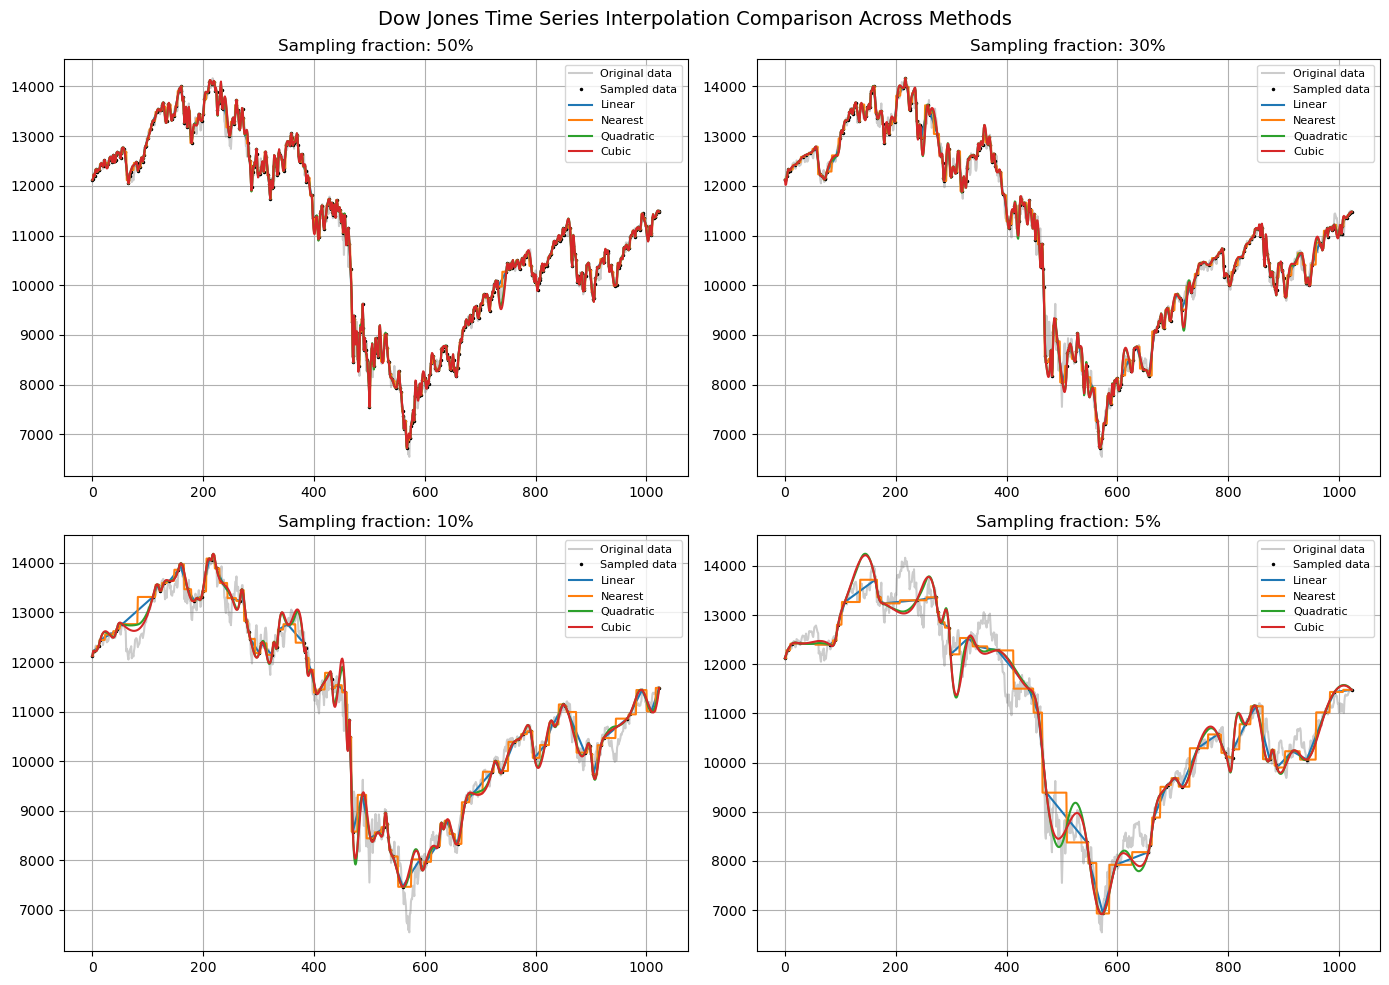

In [3]:
data = pd.read_csv("dow_jones.txt", header=None).to_numpy().flatten()

x = np.arange(len(data))
y = data
rng = np.random.default_rng(0)

# Sampling fractions
fractions = [0.50, 0.30, 0.10, 0.05]
labels = ["50%", "30%", "10%", "5%"]

samples = {}

for fraction, label in zip(fractions, labels):
    idx = rng.choice(len(y), size=int(len(y) * fraction), replace=False)
    idx = np.sort(np.unique(np.append(idx, [0, len(y) - 1])))
    samples[label] = idx

# Create interpolation functions
methods = ["linear", "nearest", "quadratic", "cubic"]
interpolators = {}

for label, idx in samples.items():
    interpolators[label] = {}

    for method in methods:
        interpolators[label][method] = interpolate.interp1d(
            x[idx], y[idx], kind=method
        )

# Full view of Dow Jones series
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, label in zip(axes, labels):
    idx = samples[label]
    ax.plot(x, y, color="gray", alpha=0.4, label="Original data")
    ax.plot(x[idx], y[idx], "k.", markersize=3, label="Sampled data")

    for method in methods:
        ax.plot(x, interpolators[label][method](x), label=method.capitalize())
        ax.set_title(f"Sampling fraction: {label}")
        ax.legend(fontsize=8)
        ax.grid(True)

plt.suptitle("Dow Jones Time Series Interpolation Comparison Across Methods", fontsize=14)
plt.tight_layout()
plt.savefig("Figures/e8_figure1.png", dpi=300)
plt.show()


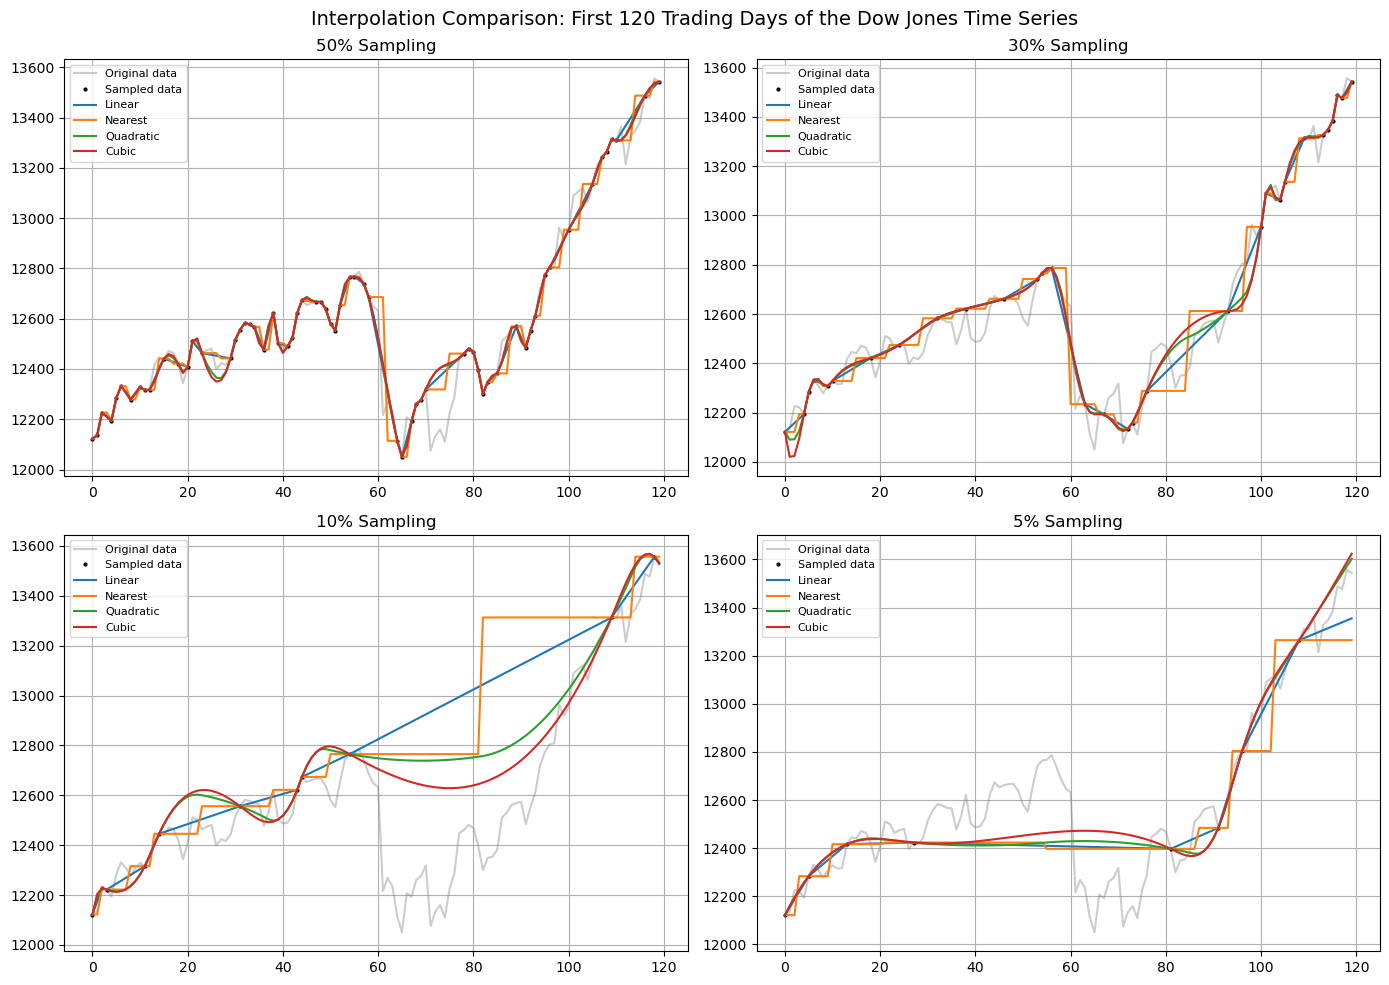

In [4]:
# Zoomed view of the first 120 trading days
zoom = 120
x_zoom = x[:zoom]
y_zoom = y[:zoom]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, label in zip(axes, labels):
    idx = samples[label]
    visible = idx < zoom

    ax.plot(x_zoom, y_zoom, color="gray", alpha=0.4, label="Original data")
    ax.plot(x[idx[visible]], y[idx[visible]], "k.", markersize=4,
            label="Sampled data")

    for method in methods:
        ax.plot(x_zoom, interpolators[label][method](x_zoom), label=method.capitalize())
        ax.set_title(f"{label} Sampling")
        ax.legend(fontsize=8)
        ax.grid(True)

plt.suptitle("Interpolation Comparison: First 120 Trading Days of the Dow Jones Time Series", fontsize=14)
plt.tight_layout()
plt.savefig("Figures/e8_figure2.png", dpi=300)
plt.show()

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

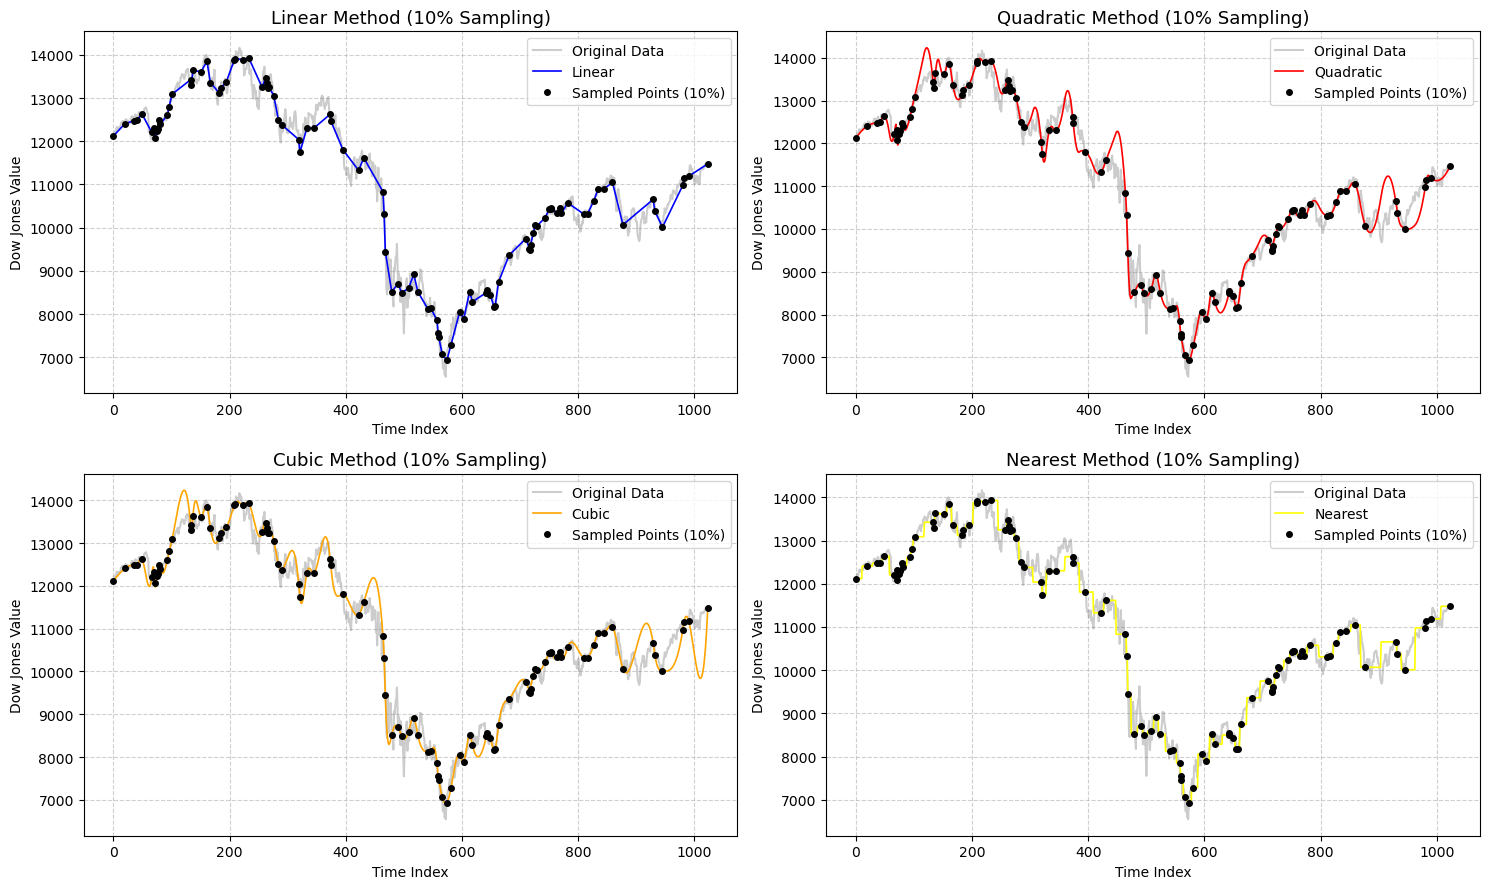

In [5]:
# Compare interpolation methods using 10% sampling

sampled_idx = np.sort(rng.choice(len(data), size=int(len(data) * 0.10), replace=False))
sampled_idx[0], sampled_idx[-1] = 0, len(data) - 1

x_sample, y_sample = x[sampled_idx], y[sampled_idx]

fig, [[ax1,ax2],[ax3,ax4]] = plt.subplots(2,2, figsize=(15,9))

axes = [ax1,ax2,ax3,ax4]
methods = ['linear', 'quadratic', 'cubic', 'nearest']
title_method = ['Linear', 'Quadratic', 'Cubic', 'Nearest']
colors = ['blue','red','orange', 'yellow']

# Loop over interpolation methods to create and plot each curve
for method, ax, color, tm in zip(methods,axes,colors,title_method):
    ax.plot(x, y, color='gray', alpha=0.4, linewidth=1.5, label='Original Data') # Plot for original data
    f_interp = interpolate.interp1d(x_sample, y_sample, kind=method) # Interpolate the data
    ax.plot(x, f_interp(x), label=method.capitalize(), linewidth=1.2, color=color) # plots the interpolated function
    ax.plot(x_sample, y_sample, 'ko', markersize=4, label='Sampled Points (10%)') # plots which points are sampled
    ax.set_title(f'{tm} Method (10% Sampling)', fontsize=13)
    ax.set_xlabel('Time Index')
    ax.set_ylabel('Dow Jones Value')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()

plt.tight_layout()
plt.savefig('Figures/e8_figure3')
plt.show()

### Problem  code summary

The code compares four interpolation methods to demonstrate their differences in reconstructing sampled data. A synthetic sine function is used to examine how closely each method reproduces a known continuous function, while real-world Dow Jones data are used to investigate how reconstruction quality changes across sampling fractions of 50%, 30%, 10%, and 5%.

---